# Liver Cancer: Model Training

[Project overview](../README.md) · [01 Data preparation](./01_data_preparation.ipynb) · [02 DLPFC](./02_DLPFC.ipynb) · [03 Drosophila embryos](./03_Drosophila%20embryos.ipynb) · [04 Embryo](./04_Embryo.ipynb) · [05 Liver cancer](./05_liver_cancer.ipynb)

This tutorial trains K-SPADA on liver cancer reference samples, then predicts query sample 4 and displays known and predicted spatial labels.

Training graph: `../../data/DLPFC/2_3_4_5_to_1_train_valid_CGraph_k_2.h5ad`. Despite its directory name, this existing file contains the liver cancer samples used by the current code. Training samples: **7, 8, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20**. Validation sample: **9**. The notebook trains for **10 epochs** using `human_gobp` pathway tokens.

Run this notebook from `tutorials/` with **Python (KSPADA_env @ d05 GPU 3)**. All documentation paths are relative to this directory. Existing code cells, input paths, and model parameters are preserved. Training uses GPU 3; the current prediction implementation runs on CPU.


In [1]:
from pathlib import Path
import anndata as ad
import torch
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../data/DLPFC").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "model_training"
TRAIN_VALID_H5AD = DATA_DIR / "2_3_4_5_to_1_train_valid_CGraph_k_2.h5ad"
PROJECT_NAME = "liver_cancer_2_3_4_5_to_1"

TRAIN_SAMPLES = ['7', '8', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20']
VALIDATION_SAMPLES = ['9']
PATHWAY_NAME = "human_gobp"
LABEL_NAME = "Celltype"
MAX_GENES_PER_PATHWAY = 300
MAX_PATHWAY_TOKENS = 300
MASK_RATIO = 0.015
UNANNOTATED_TOKENS = 1
STANDARD_BATCH_SIZE = 8
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
LEARNING_RATE = 0.001
WEIGHT_DECAY = 5e-5
EPOCHS = 10
FINAL_LEARNING_RATE_RATIO = 0.01
GRAPH_BATCH_SIZE = 128
SPATIAL_NEIGHBORS = 4
LAMBDA_REGULARIZATION = 1e-6
RANDOM_SEED = 2026

## Step 1 — Select the GPU

**Execution result (2026-11-13):** CUDA was available on `d05`. The `KSPADA_env` kernel used physical GPU 3 (NVIDIA A100 80GB PCIe), exposed as `cuda:0`.


In [2]:
if not torch.cuda.is_available():
    raise RuntimeError("CUDA is unavailable. Select a GPU-enabled KSPADA kernel before training.")

torch.cuda.set_device(0)
TRAINING_DEVICE = torch.device("cuda:0")

## Step 2 — Validate the prepared graph file

**Execution result:** input-file checks, required graph fields, and the expected sample split passed. The prepared graph contains **59,953 observations × 3,000 genes**.


In [3]:
if not TRAIN_VALID_H5AD.is_file():
    raise FileNotFoundError(TRAIN_VALID_H5AD)

KSPADA.validate_cgraph_fields(TRAIN_VALID_H5AD, mode="train")
training_adata = ad.read_h5ad(TRAIN_VALID_H5AD, backed="r")
actual_samples = set(training_adata.obs["batch"].astype(str).unique())
expected_samples = set(TRAIN_SAMPLES + VALIDATION_SAMPLES)
training_adata.file.close()
if actual_samples != expected_samples:
    raise ValueError(
        f"Sample mismatch: expected {sorted(expected_samples)}, found {sorted(actual_samples)}"
    )

## Step 3 — Train the model

**Execution result:** all **10 training epochs** completed. The final progress output reports training accuracy **99.4%** and validation accuracy **72.2%** (rounded as printed by the original code). Checkpoint: `../outputs/model_training/liver_cancer_2_3_4_5_to_1/model-9.pth`.


In [4]:
model_directory = KSPADA.train_model(
    adata_input=TRAIN_VALID_H5AD,
    project=PROJECT_NAME,
    output_dir=OUTPUT_DIR,
    gmt_path=PATHWAY_NAME,
    label_name=LABEL_NAME,
    train_batches=TRAIN_SAMPLES,
    use_gcn=True,
    pre_weights="",
    max_g=MAX_GENES_PER_PATHWAY,
    max_gs=MAX_PATHWAY_TOKENS,
    mask_ratio=MASK_RATIO,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=STANDARD_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
    epochs=EPOCHS,
    lrf=FINAL_LEARNING_RATE_RATIO,
    batch_size_gcn=GRAPH_BATCH_SIZE,
    neighbor=SPATIAL_NEIGHBORS,
    lambda_reg=LAMBDA_REGULARIZATION,
    random_seed=RANDOM_SEED,
)

batch_size_gcn: 128
lambda_reg: 1e-06
neighbor: 4
num_head: 4
depth: 2
embed_dim: 48
weight_decay: 5e-05
random_seed: 2026
cuda:0


torch.Size([2, 221032])
torch.Size([2, 18780])
enhance:  torch.Size([2, 221032])
enhance:  torch.Size([2, 18780])


edge_index_train shape before merge: torch.Size([2, 476340])
edge_index_valid shape before merge: torch.Size([2, 48440])
edge_index_train shape after merge: torch.Size([2, 479099])
edge_index_valid shape after merge: torch.Size([2, 48674])


Mask loaded!
use_gcn:True
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


Model builded!



  0%|          | 0/939 [00:00<?, ?it/s]

... (345 outputs left out)


[train epoch 9] loss: 0.017, acc: 0.994: 100%|██████████| 939/939 [02:24<00:00,  6.50it/s]


  0%|          | 0/95 [00:00<?, ?it/s]


[valid epoch 9] loss: 2.359, acc: 0.722: 100%|██████████| 95/95 [00:03<00:00, 27.21it/s]

Training finished!


## Notes

- Replace the sample names with values present in the prepared graph file.
- Training and prediction must use the same embedding dimension, Transformer depth, attention-head count, and graph settings.

# Liver Cancer: Prediction and Visualization

This continuation predicts query samples **4, 5, 6** with the existing trained checkpoint. The training section and all code cells are preserved.

**Execution context:** the runner supplied `QUERY_H5AD` and the sample-specific `QUERY_SAMPLE` aliases required by the existing cells. It also set sample-specific `PREDICTION_H5AD` and `FIGURE_PREFIX` values before each prediction. These values are recorded in the prediction cell metadata; they are runtime context, not changes to the code cells.


In [5]:
from pathlib import Path
import KSPADA

PROJECT_ROOT = Path("..").resolve()
DATA_DIR = Path("../../../../TOSICA-main/data/liver_cancer").resolve()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "prediction"
MODEL_DIR = PROJECT_ROOT / "outputs" / "model_training" / "liver_cancer_2_3_4_5_to_1"
MODEL_WEIGHT_PATH = MODEL_DIR / "model-9.pth"
QUERY_SAMPLE = "4"
QUERY_H5AD_1 = DATA_DIR / "liver_cancer_query_4_path_scores_graph_k_2.h5ad"
QUERY_H5AD_2 = DATA_DIR / "liver_cancer_query_5_path_scores_graph_k_2.h5ad"
QUERY_H5AD_3 = DATA_DIR / "liver_cancer_query_6_path_scores_graph_k_2.h5ad"
REFERENCE_H5AD = Path("../../../../TOSICA-main/data/liver_cancer/all_hvg_3000.h5ad").resolve()
PREDICTION_H5AD = OUTPUT_DIR / "query_prediction.h5ad"
FIGURE_PREFIX = OUTPUT_DIR / "query_prediction_spatial"

PREDICTION_CUTOFF = 0.1
USE_GCN = True
UNANNOTATED_TOKENS = 1
PREDICTION_BATCH_SIZE = 50
EMBEDDING_DIM = 48
TRANSFORMER_DEPTH = 2
ATTENTION_HEADS = 4
POINT_SIZE = 50

## Step 1 — Validate input paths

**Execution result:** all 3 query inputs, the trained checkpoint, and plotting reference files were found. Each query has the same genes in the same order as the training input.


In [6]:
for required_path in [MODEL_DIR, MODEL_WEIGHT_PATH, QUERY_H5AD, REFERENCE_H5AD]:
    if not required_path.exists():
        raise FileNotFoundError(required_path)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Step 2 — Predict the query samples

**Execution result:** all configured queries completed. Accuracy was calculated after prediction by comparing against the existing `Celltype` column.

| Query sample | Observations | Accuracy | Prediction file |
| --- | ---: | ---: | --- |
| 4 | 2,755 | 86.10% | [h5ad](../outputs/prediction/query_prediction_4.h5ad) |
| 5 | 2,947 | 97.32% | [h5ad](../outputs/prediction/query_prediction_5.h5ad) |
| 6 | 3,157 | 86.16% | [h5ad](../outputs/prediction/query_prediction_6.h5ad) |


In [7]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD_1,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 16530])
edge_index after merge shape: torch.Size([2, 16667])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


## Step 3 — Create spatial plots

**Execution result:** each query has its own embedded spatial comparison in the corresponding plotting cell. All PNG (600 DPI), PDF, and SVG exports were checked.

| Query sample | PNG | PDF | SVG |
| --- | --- | --- | --- |
| 4 | [PNG](../outputs/prediction/query_prediction_spatial_4.png) | [PDF](../outputs/prediction/query_prediction_spatial_4.pdf) | [SVG](../outputs/prediction/query_prediction_spatial_4.svg) |
| 5 | [PNG](../outputs/prediction/query_prediction_spatial_5.png) | [PDF](../outputs/prediction/query_prediction_spatial_5.pdf) | [SVG](../outputs/prediction/query_prediction_spatial_5.svg) |
| 6 | [PNG](../outputs/prediction/query_prediction_spatial_6.png) | [PDF](../outputs/prediction/query_prediction_spatial_6.pdf) | [SVG](../outputs/prediction/query_prediction_spatial_6.svg) |


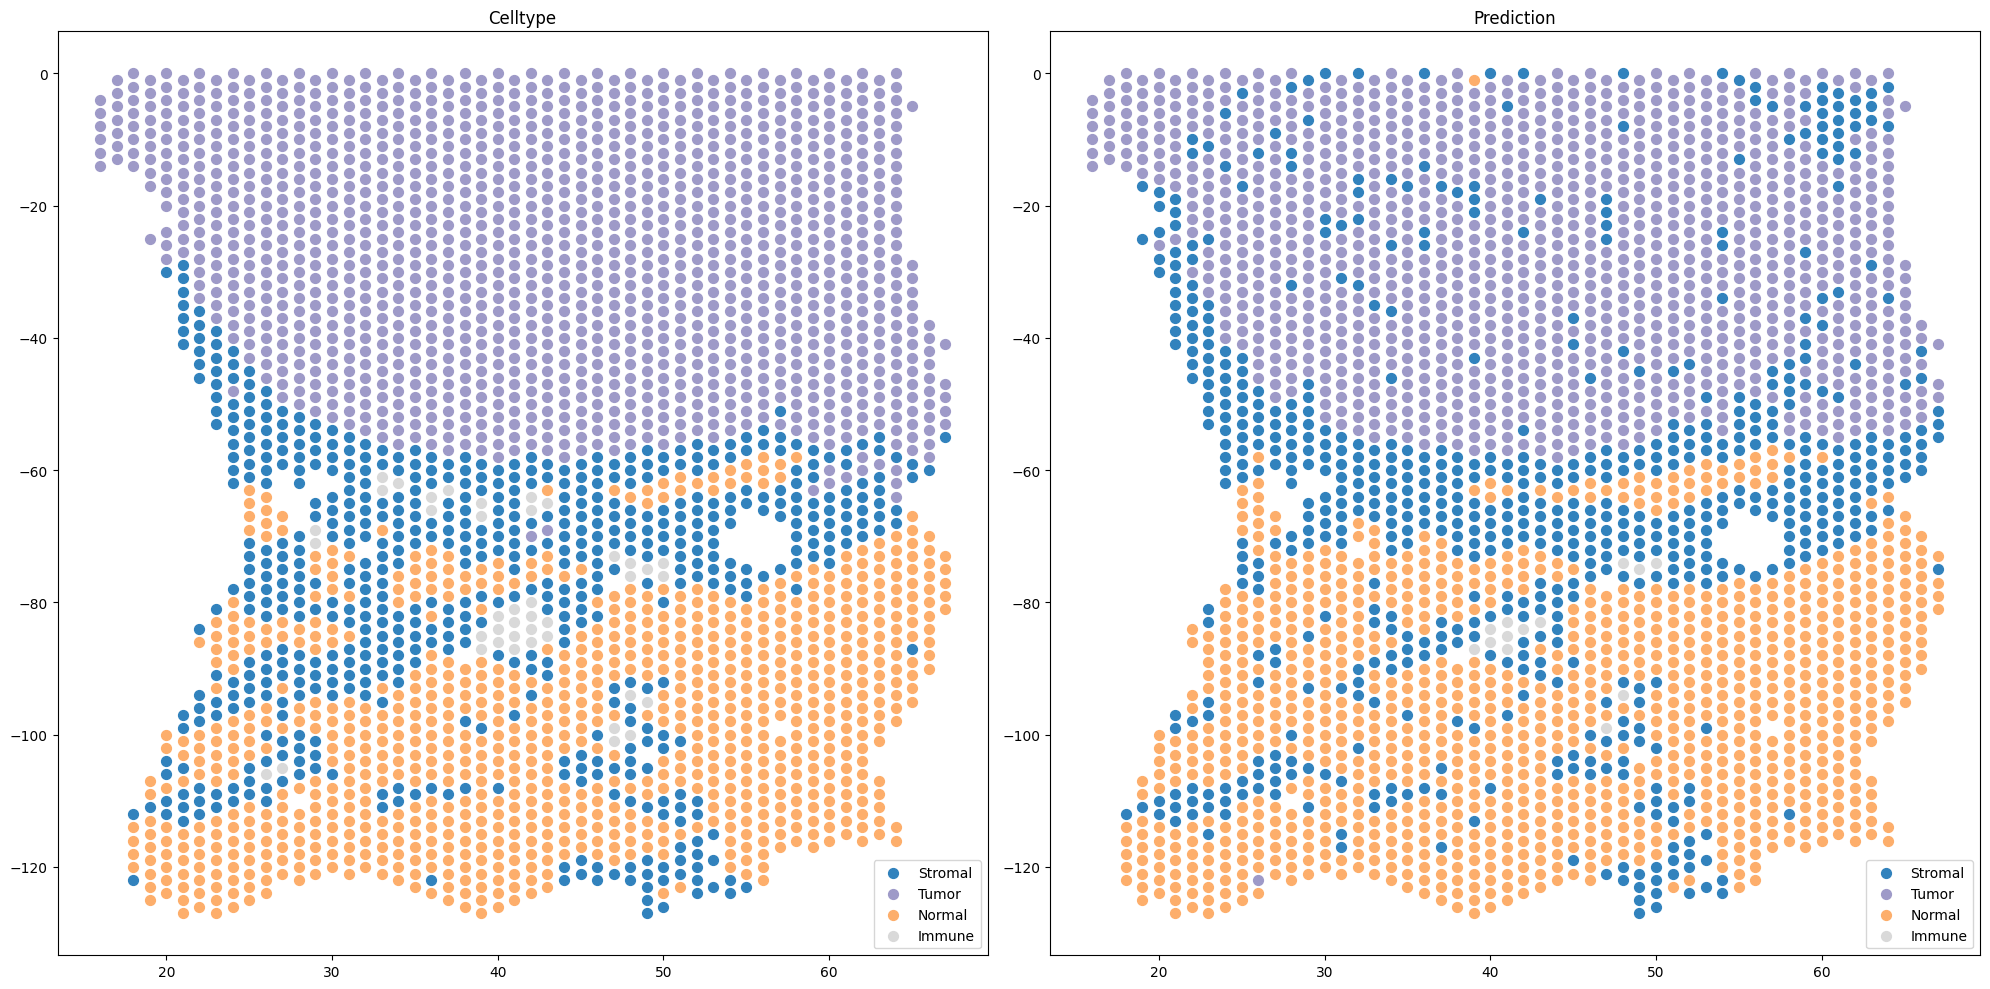

In [8]:
import anndata as ad
import matplotlib.pyplot as plt

# Use the full liver dataset to retain the source script's label order.
color_reference = ad.read_h5ad(REFERENCE_H5AD, backed="r")
color_labels = color_reference.obs["Celltype"].unique().tolist()
color_reference.file.close()
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].legend()
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].legend()
axes[1].set_title("Prediction")
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


In [9]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD_2,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 17682])
edge_index after merge shape: torch.Size([2, 17829])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


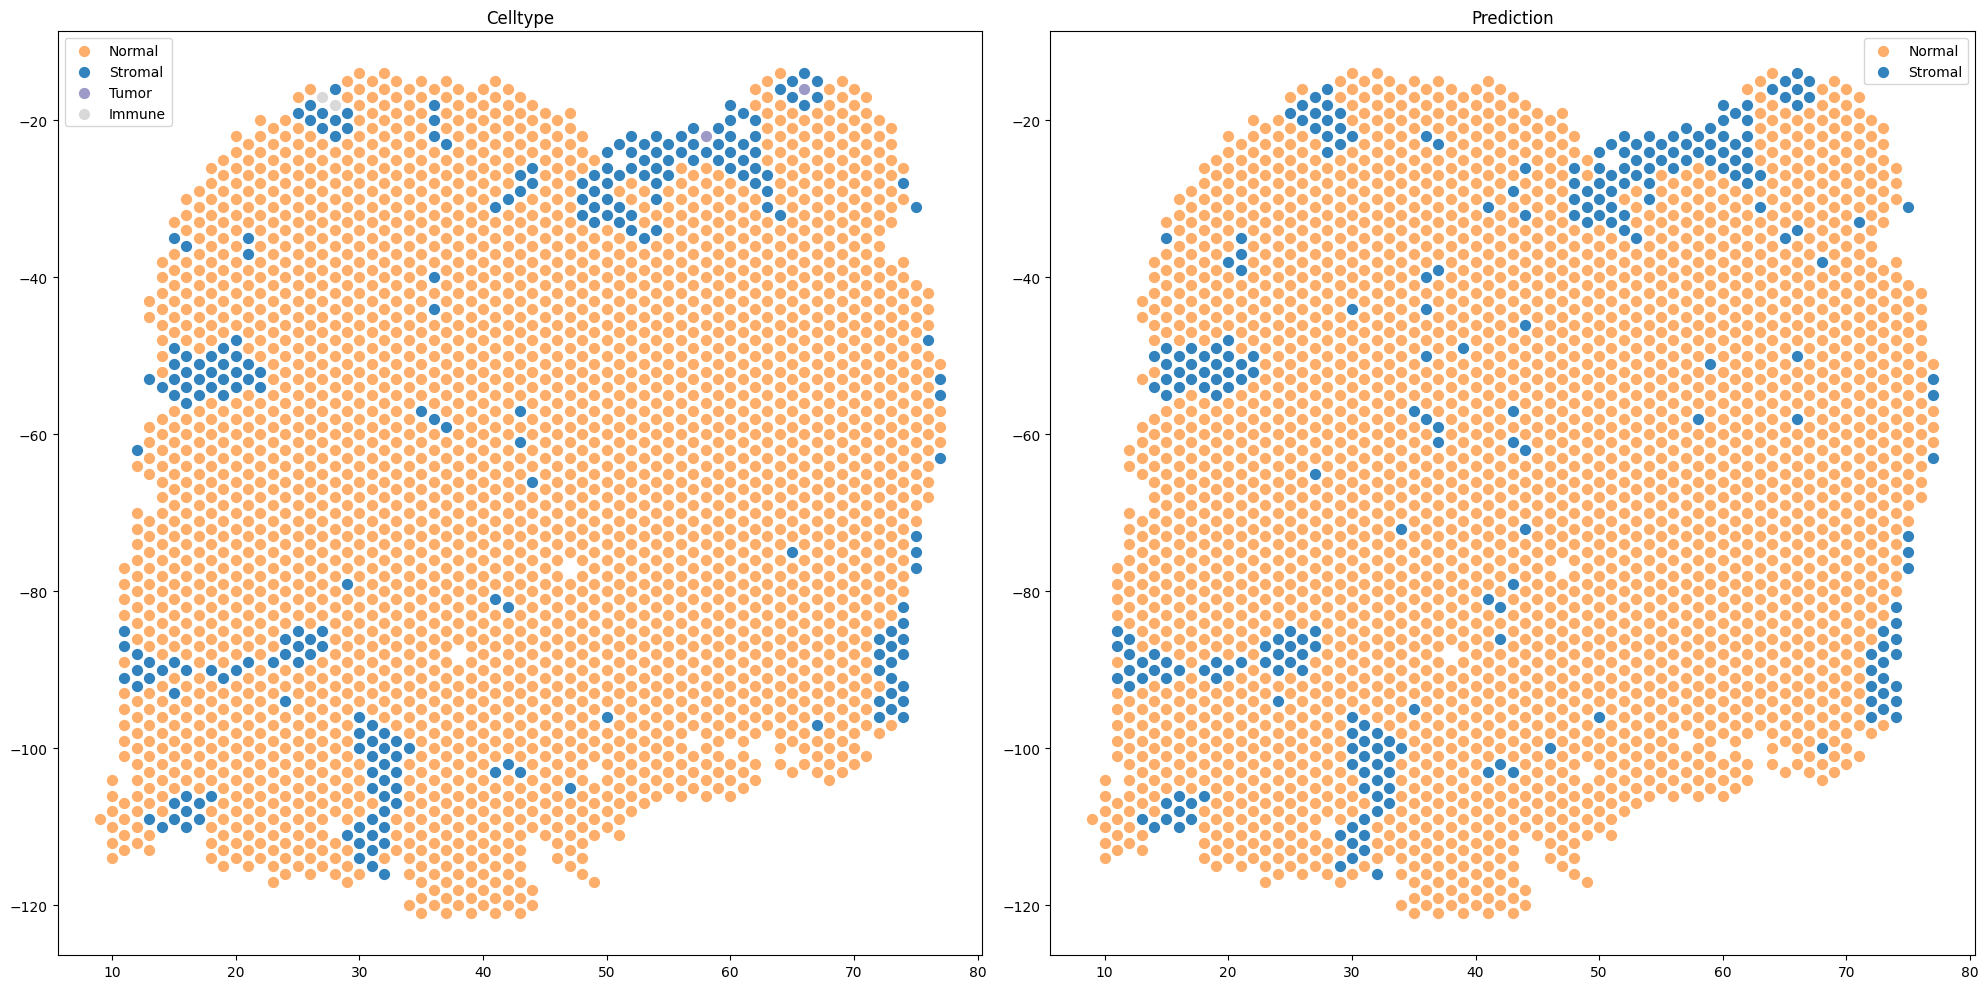

In [10]:
import anndata as ad
import matplotlib.pyplot as plt

# Use the full liver dataset to retain the source script's label order.
color_reference = ad.read_h5ad(REFERENCE_H5AD, backed="r")
color_labels = color_reference.obs["Celltype"].unique().tolist()
color_reference.file.close()
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].legend()
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].legend()
axes[1].set_title("Prediction")
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


In [11]:
prediction_adata = KSPADA.predict_model(
    adata_input=QUERY_H5AD_3,
    model_dir=MODEL_DIR,
    model_weight_path=MODEL_WEIGHT_PATH,
    output_path=PREDICTION_H5AD,
    prediction_batches=[QUERY_SAMPLE],
    cutoff=PREDICTION_CUTOFF,
    use_gcn=USE_GCN,
    n_unannotated=UNANNOTATED_TOKENS,
    batch_size=PREDICTION_BATCH_SIZE,
    embed_dim=EMBEDDING_DIM,
    depth=TRANSFORMER_DEPTH,
    num_heads=ATTENTION_HEADS,
)

cpu
depth: 2
num_heads: 4
embed_dim: 48
use_gcn: True
prediction_mode: full_graph
neighbor: 6
edge_index shape: torch.Size([2, 18942])
edge_index after merge shape: torch.Size([2, 19099])
use_position_encode: False
embed_dim_heads: 48
num_heads: 4


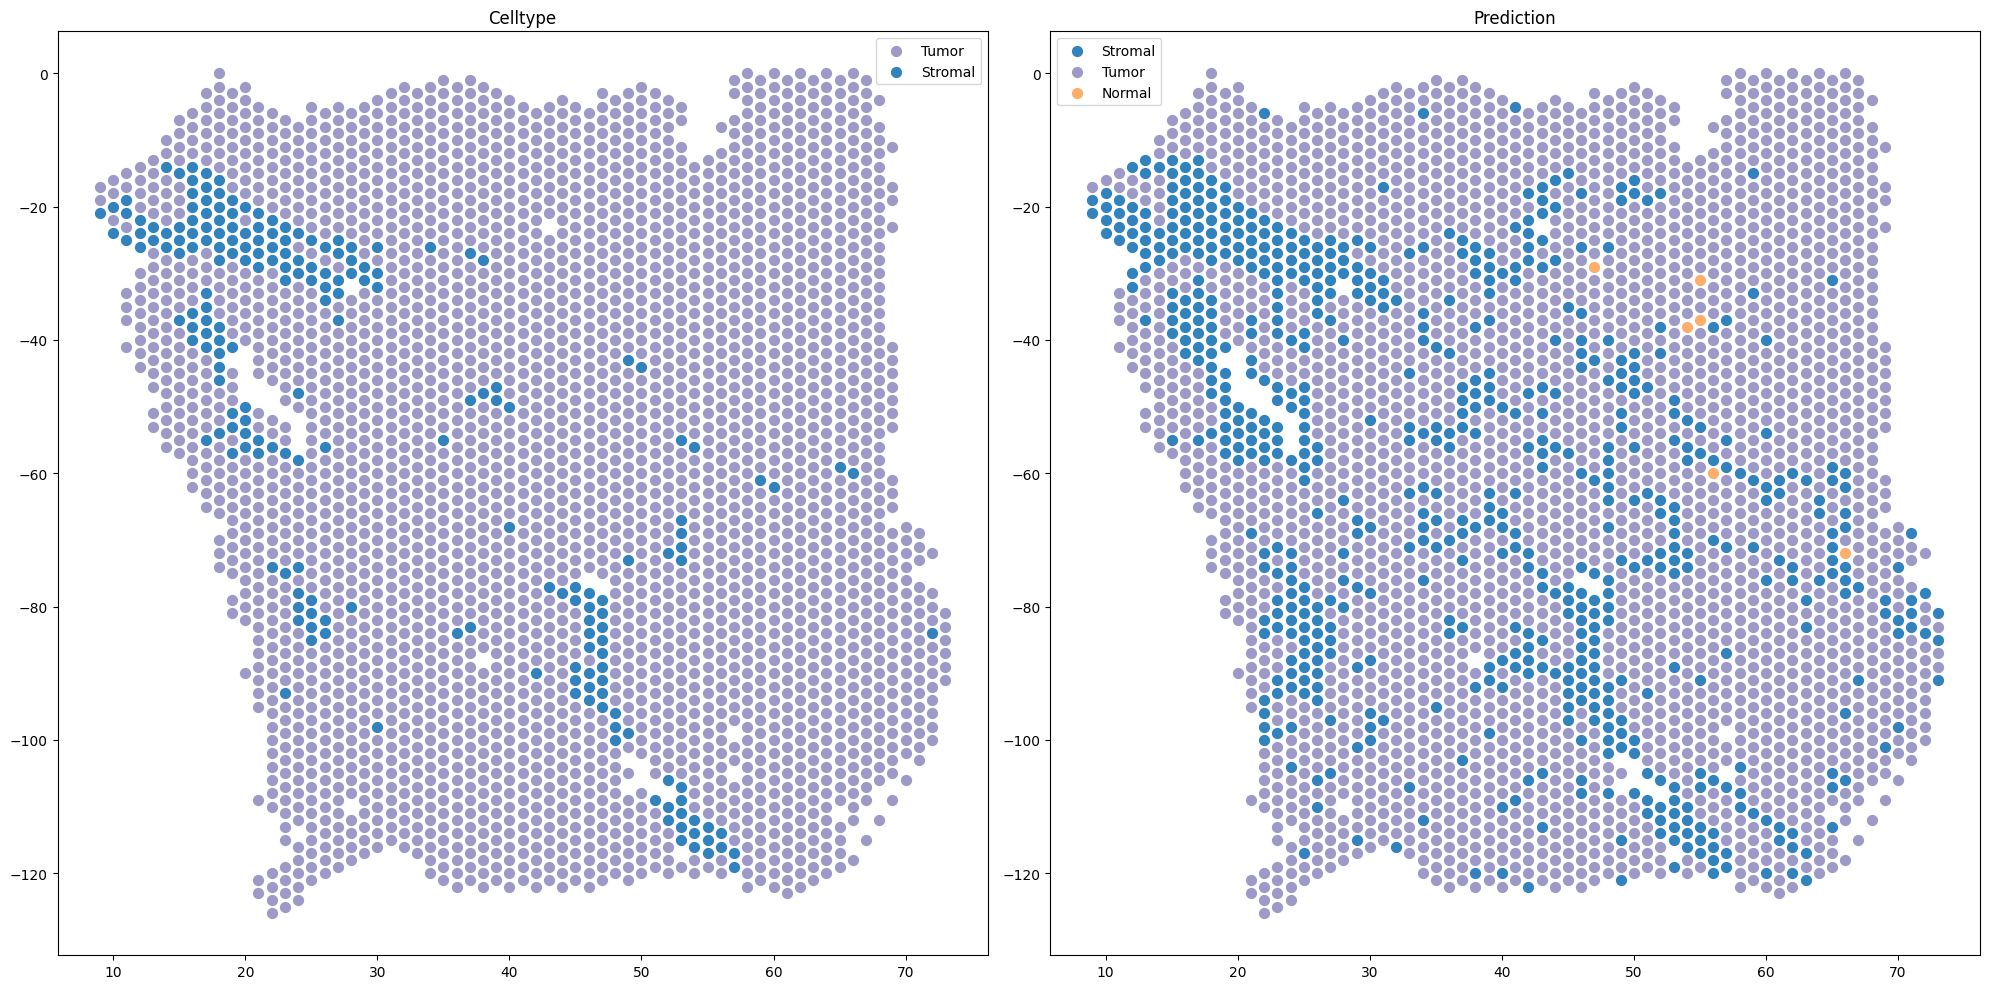

In [12]:
import anndata as ad
import matplotlib.pyplot as plt

# Use the full liver dataset to retain the source script's label order.
color_reference = ad.read_h5ad(REFERENCE_H5AD, backed="r")
color_labels = color_reference.obs["Celltype"].unique().tolist()
color_reference.file.close()
color_map = plt.get_cmap("tab20c", len(color_labels))
label_colors = {label: color_map(index) for index, label in enumerate(color_labels)}

# Match the source script's spatial orientation and side-by-side comparison.
x_coordinates = prediction_adata.obs["x"]
y_coordinates = -prediction_adata.obs["y"]
celltypes = prediction_adata.obs["Celltype"].astype(str)
predictions = prediction_adata.obs["Prediction"].astype(str)
figure, axes = plt.subplots(1, 2, figsize=(20, 10))
for celltype in celltypes.unique():
    matching_cells = celltypes == celltype
    axes[0].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[celltype], label=celltype, s=POINT_SIZE)
axes[0].legend()
axes[0].set_title("Celltype")
for prediction in predictions.unique():
    matching_cells = predictions == prediction
    axes[1].scatter(x_coordinates[matching_cells], y_coordinates[matching_cells], color=label_colors[prediction], label=prediction, s=POINT_SIZE)
axes[1].legend()
axes[1].set_title("Prediction")
plt.tight_layout()

# Preserve the tutorial's high-resolution raster and vector exports.
figure.savefig(FIGURE_PREFIX.with_suffix(".png"), dpi=600, bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".pdf"), bbox_inches="tight")
figure.savefig(FIGURE_PREFIX.with_suffix(".svg"), bbox_inches="tight")
plt.show()


## Notes

- Query genes must match the model gene names and gene order.
- Replace `QUERY_SAMPLE` with the value stored in `adata.obs["batch"]` for the query graph.